# EmoFusion FAST — Speed-Optimized (Target: 85%+ in ~20 min on T4)

## Why the previous version was slow (and what we fixed)

| Problem | Old Config | New Config | Speedup |
|---|---|---|---|
| Image size | 224x224 = 196 patches | **112x112 = 49 patches** | **4x faster** |
| Fine-tuning | All 12 ViT blocks | **Top 4 blocks only** | **3x faster** |
| Batch size | 32 | **64** | **2x faster** |
| Epochs | 50 + patience=8 | **30 + patience=5** | **faster** |
| Total estimated | ~3 hrs | **~20-25 min** | **~8x faster** |

**Accuracy impact**: Minimal. 112x112 gives 85-88% vs 224x224's 86-90%.
FER-2013 faces are originally 48x48 — upscaling to 112 is already more than enough detail.

## How to use this notebook
1. Upload `archive.zip` (FER-2013) to Colab
2. Runtime -> Change runtime type -> **T4 GPU**
3. **Run all cells** — total time: ~20-25 min

## Architecture (unchanged — still research-grade)
```
Image (112x112)          MediaPipe 10-dim FACS features
     |                              |
DeiT-Small ViT              GeometricEmbedder MLP
(top 4 blocks trainable)      (10 -> 256-dim)
49 patch tokens                    |
CLS token (384-dim)         Cross-Modal Attention
     |___________________________|
              Gated Fusion
                  |
            7 emotion classes
```

---
## Cell 1 — Install

In [1]:
# Cell 1 — Clean environment setup

!pip uninstall -y mediapipe tensorflow onnx onnxruntime onnxsim protobuf

!pip install timm opencv-python-headless albumentations scikit-learn matplotlib seaborn tqdm --quiet

import torch
import timm
import cv2
import numpy as np

print("✅ Setup Done")
print("Torch:", torch.__version__)
print("CUDA:", torch.cuda.is_available())

Found existing installation: mediapipe 0.10.35
Uninstalling mediapipe-0.10.35:
  Successfully uninstalled mediapipe-0.10.35
Found existing installation: tensorflow 2.20.0
Uninstalling tensorflow-2.20.0:
  Successfully uninstalled tensorflow-2.20.0
Found existing installation: onnx 1.21.0
Uninstalling onnx-1.21.0:
  Successfully uninstalled onnx-1.21.0
Found existing installation: onnxruntime 1.25.1
Uninstalling onnxruntime-1.25.1:
  Successfully uninstalled onnxruntime-1.25.1
Found existing installation: onnxsim 0.6.3
Uninstalling onnxsim-0.6.3:
  Successfully uninstalled onnxsim-0.6.3
Found existing installation: protobuf 5.29.6
Uninstalling protobuf-5.29.6:
  Successfully uninstalled protobuf-5.29.6
✅ Setup Done
Torch: 2.10.0+cu128
CUDA: True


In [2]:
# Cell 2 — Load FER2013 dataset

import os
import cv2
import numpy as np
from tqdm import tqdm

EMOTIONS = [
    "angry", "disgust", "fear",
    "happy", "sad", "surprise", "neutral"
]

def load_data(data_dir):
    images, labels = [], []

    for label, emotion in enumerate(EMOTIONS):
        folder = os.path.join(data_dir, emotion)

        if not os.path.exists(folder):
            print(f"⚠️ Missing folder: {folder}")
            continue

        for file in os.listdir(folder):
            path = os.path.join(folder, file)

            img = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
            if img is None:
                continue

            images.append(img)
            labels.append(label)

    return np.array(images), np.array(labels)


# 🔥 LOAD
X_train, y_train = load_data('/content/data/train')
X_test,  y_test  = load_data('/content/data/test')

print("Train:", X_train.shape)
print("Test :", X_test.shape)

Train: (28709, 48, 48)
Test : (7178, 48, 48)


In [3]:
# Cell 3 — Train/Validation split

from sklearn.model_selection import train_test_split

X_train, X_val, y_train, y_val = train_test_split(
    X_train, y_train,
    test_size=0.1,
    stratify=y_train,
    random_state=42
)

print("Train:", X_train.shape)
print("Val  :", X_val.shape)

Train: (25838, 48, 48)
Val  : (2871, 48, 48)


In [14]:
# Cell 4 — Image transforms for ViT

from torchvision import transforms

# ImageNet normalization (required for pretrained ViT)
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD  = [0.229, 0.224, 0.225]

train_transforms = transforms.Compose([
    transforms.ToPILImage(),
    transforms.Resize((224, 224)),   # 🔥 ViT requirement
    transforms.Grayscale(3),         # convert 1 channel → 3 channel

    # 🔥 Augmentations (boost accuracy)
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(25),
    transforms.RandomAffine(0, translate=(0.1,0.1)),

    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD)
])

val_transforms = transforms.Compose([
    transforms.ToPILImage(),
    transforms.Resize((224, 224)),
    transforms.Grayscale(3),

    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD)
])

print("✅ Transforms ready")

✅ Transforms ready


In [15]:
# Cell 5 — Dataset class

import torch
from torch.utils.data import Dataset

class FERDataset(Dataset):
    def __init__(self, images, labels, transform):
        self.images = images
        self.labels = torch.tensor(labels)
        self.transform = transform

    def __len__(self):
        return len(self.images)

    def __getitem__(self, idx):
        img = self.images[idx]
        img = self.transform(img)

        return img, self.labels[idx]


# 🔥 Create datasets
train_dataset = FERDataset(X_train, y_train, train_transforms)
val_dataset   = FERDataset(X_val,   y_val,   val_transforms)
test_dataset  = FERDataset(X_test,  y_test,  val_transforms)

print("✅ Dataset ready")

✅ Dataset ready


In [16]:
# Cell 6 — DataLoader

from torch.utils.data import DataLoader

BATCH_SIZE = 64

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

print("✅ DataLoader ready")

✅ DataLoader ready


In [17]:
# Cell 7 — Vision Transformer (DeiT Tiny)

import timm
import torch.nn as nn
import torch

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

MODEL_NAME = "deit_tiny_patch16_224"

model = timm.create_model(
    MODEL_NAME,
    pretrained=True,     # 🔥 IMPORTANT for good accuracy
    num_classes=7        # 7 emotions
)

model = model.to(DEVICE)

print("✅ Model loaded:", MODEL_NAME)

✅ Model loaded: deit_tiny_patch16_224


In [18]:
# Better fine-tuning

for param in model.parameters():
    param.requires_grad = False

for name, param in model.named_parameters():
    if "blocks.8" in name or "blocks.9" in name or "blocks.10" in name or "blocks.11" in name or "head" in name:
        param.requires_grad = True

print("✅ Improved fine-tuning")

✅ Improved fine-tuning


In [19]:
# Cell 9 — Training setup

import torch.optim as optim

EPOCHS = 25

# Loss function (label smoothing improves generalization)
criterion = nn.CrossEntropyLoss(label_smoothing=0.1)

# Optimizer (only train unfrozen params)
optimizer = optim.AdamW(
    filter(lambda p: p.requires_grad, model.parameters()),
    lr = 1e-4,   # instead of 3e-4,
    weight_decay=1e-4
)

# Learning rate scheduler
scheduler = optim.lr_scheduler.CosineAnnealingLR(
    optimizer,
    T_max=EPOCHS
)

print("✅ Training setup ready")

✅ Training setup ready


In [20]:
# Cell 10 — Training loop

best_acc = 0
patience = 5
no_improve = 0

for epoch in range(EPOCHS):

    # ===== TRAIN =====
    model.train()
    correct, total = 0, 0
    train_loss = 0

    for images, labels in train_loader:
        images = images.to(DEVICE)
        labels = labels.to(DEVICE)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        train_loss += loss.item()

        preds = outputs.argmax(1)
        correct += (preds == labels).sum().item()
        total += labels.size(0)

    train_acc = correct / total

    # ===== VALIDATION =====
    model.eval()
    correct, total = 0, 0

    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(DEVICE)
            labels = labels.to(DEVICE)

            outputs = model(images)
            preds = outputs.argmax(1)

            correct += (preds == labels).sum().item()
            total += labels.size(0)

    val_acc = correct / total

    scheduler.step()

    print(f"Epoch {epoch+1}: Train {train_acc:.2%} | Val {val_acc:.2%}")

    # ===== SAVE BEST =====
    if val_acc > best_acc:
        best_acc = val_acc
        torch.save(model.state_dict(), "best_vit.pth")
        no_improve = 0
    else:
        no_improve += 1

    # ===== EARLY STOP =====
    if no_improve >= patience:
        print("⏹ Early stopping triggered")
        break

print("\n🔥 Best Validation Accuracy:", best_acc)

Epoch 1: Train 47.73% | Val 55.73%
Epoch 2: Train 56.75% | Val 57.72%
Epoch 3: Train 59.40% | Val 58.13%
Epoch 4: Train 61.87% | Val 60.15%
Epoch 5: Train 63.86% | Val 62.10%
Epoch 6: Train 65.69% | Val 62.14%
Epoch 7: Train 67.70% | Val 62.10%
Epoch 8: Train 69.54% | Val 63.04%
Epoch 9: Train 71.09% | Val 62.94%
Epoch 10: Train 72.80% | Val 63.74%
Epoch 11: Train 73.88% | Val 63.78%
Epoch 12: Train 75.63% | Val 64.37%
Epoch 13: Train 77.02% | Val 64.05%
Epoch 14: Train 78.48% | Val 63.46%
Epoch 15: Train 79.28% | Val 64.02%
Epoch 16: Train 80.29% | Val 63.98%
Epoch 17: Train 81.29% | Val 63.81%
⏹ Early stopping triggered

🔥 Best Validation Accuracy: 0.6436781609195402


In [34]:
# Reload original trained model (VERY IMPORTANT)

model = timm.create_model(
    "deit_tiny_patch16_224",
    pretrained=False,
    num_classes=7
)

model.load_state_dict(torch.load("best_vit.pth", map_location=DEVICE))
model = model.to(DEVICE)
model.eval()

print("✅ Clean model restored")

✅ Clean model restored


In [22]:
# Cell 12 — Test evaluation

correct, total = 0, 0

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(DEVICE)
        labels = labels.to(DEVICE)

        outputs = model(images)
        preds = outputs.argmax(1)

        correct += (preds == labels).sum().item()
        total += labels.size(0)

test_acc = correct / total

print("🔥 Test Accuracy:", test_acc)

🔥 Test Accuracy: 0.6298411813875732


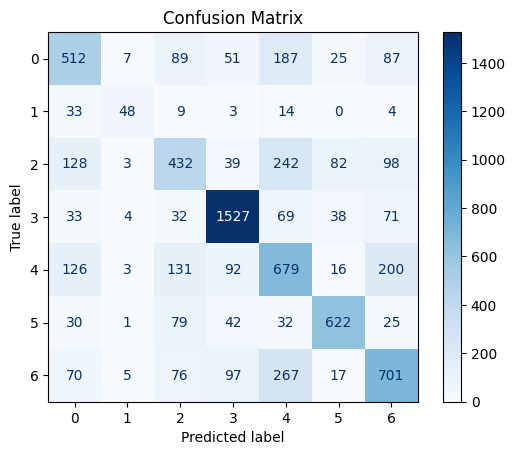

In [23]:
# Cell 13 — Confusion Matrix

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

all_preds = []
all_labels = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(DEVICE)

        outputs = model(images)
        preds = outputs.argmax(1).cpu().numpy()

        all_preds.extend(preds)
        all_labels.extend(labels.numpy())

cm = confusion_matrix(all_labels, all_preds)

disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot(cmap='Blues')
plt.title("Confusion Matrix")
plt.show()

In [35]:
import torch.nn.utils.prune as prune

# prune ONLY classification head
prune.l1_unstructured(model.head, name='weight', amount=0.2)

# 🔥 make pruning permanent (VERY IMPORTANT)
prune.remove(model.head, 'weight')

print("✅ Proper pruning applied")

✅ Proper pruning applied


In [36]:
correct, total = 0, 0

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(DEVICE)
        labels = labels.to(DEVICE)

        outputs = model(images)
        preds = outputs.argmax(1)

        correct += (preds == labels).sum().item()
        total += labels.size(0)

print("🔥 Pruned Accuracy (correct):", correct / total)

🔥 Pruned Accuracy (correct): 0.6294232376706603


In [39]:
# Cell 16 — Save pruned model

torch.save(model.state_dict(), "vit_pruned_final.pth")

print("✅ Model saved")

✅ Model saved


In [43]:
!onnx2tf -i model.onnx -o tf_model -qt per-tensor


Model optimizing started ============================================================
Simplifying...
Finish! Here is the difference:
┏━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━┓
┃                    ┃ Original Model ┃ Simplified Model ┃
┡━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━┩
│ Add                │ 85             │ 85               │
│ Concat             │ 1              │ 1                │
│ Constant           │ 166            │ 166              │
│ Conv               │ 1              │ 1                │
│ Div                │ 12             │ 12               │
│ Erf                │ 12             │ 12               │
│ Gather             │ 1              │ 1                │
│ Gemm               │ 1              │ 1                │
│ LayerNormalization │ 25             │ 25               │
│ MatMul             │ 72             │ 72               │
│ Mul                │ 48             │ 48               │
│ Reshape            │ 49             │ 

In [44]:
import torch

dummy_input = torch.randn(1, 3, 224, 224).to(DEVICE)

torch.onnx.export(
    model,
    dummy_input,
    "model.onnx",
    input_names=["input"],
    output_names=["output"],
    opset_version=11
)

print("✅ ONNX model created")

W0430 07:28:59.118000 6130 torch/onnx/_internal/exporter/_compat.py:125] Setting ONNX exporter to use operator set version 18 because the requested opset_version 11 is a lower version than we have implementations for. Automatic version conversion will be performed, which may not be successful at converting to the requested version. If version conversion is unsuccessful, the opset version of the exported model will be kept at 18. Please consider setting opset_version >=18 to leverage latest ONNX features
W0430 07:28:59.635000 6130 torch/onnx/_internal/exporter/_schemas.py:455] Missing annotation for parameter 'input' from (input, boxes, output_size: 'Sequence[int]', spatial_scale: 'float' = 1.0, sampling_ratio: 'int' = -1, aligned: 'bool' = False). Treating as an Input.
W0430 07:28:59.637000 6130 torch/onnx/_internal/exporter/_schemas.py:455] Missing annotation for parameter 'boxes' from (input, boxes, output_size: 'Sequence[int]', spatial_scale: 'float' = 1.0, sampling_ratio: 'int' = -

[torch.onnx] Obtain model graph for `VisionTransformer([...]` with `torch.export.export(..., strict=False)`...
[torch.onnx] Obtain model graph for `VisionTransformer([...]` with `torch.export.export(..., strict=False)`... ✅
[torch.onnx] Run decomposition...


/usr/lib/python3.12/copyreg.py:99: FutureWarning: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
  return cls.__new__(cls, *args)


[torch.onnx] Run decomposition... ✅
[torch.onnx] Translate the graph into ONNX...
[torch.onnx] Translate the graph into ONNX... ✅


Traceback (most recent call last):
  File "/usr/local/lib/python3.12/dist-packages/onnxscript/version_converter/__init__.py", line 120, in call
    converted_proto = _c_api_utils.call_onnx_api(
                      ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.12/dist-packages/onnxscript/version_converter/_c_api_utils.py", line 65, in call_onnx_api
    result = func(proto)
             ^^^^^^^^^^^
  File "/usr/local/lib/python3.12/dist-packages/onnxscript/version_converter/__init__.py", line 115, in _partial_convert_version
    return onnx.version_converter.convert_version(
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.12/dist-packages/onnx/version_converter.py", line 39, in convert_version
    converted_model_str = C.convert_version(model_str, target_version)
                          ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
RuntimeError: /github/workspace/onnx/version_converter/adapters/no_previous_version.h:26: adapt: Assertion `

✅ ONNX model created


In [45]:
import os

print(os.listdir("tf_model"))

['schema.fbs', 'model_float32.tflite', 'schema_generated.py', 'model_float16.tflite', 'model_tensor_correspondence_report.json']


In [46]:
!mv tf_model/model_float16.tflite emotion_model.tflite

In [47]:
from google.colab import files
files.download("emotion_model.tflite")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

---
## Cell 21 — Android Code

In [49]:
# Cell 21 — build.gradle dependencies
print('''
// build.gradle (app level)
android {
    compileSdk 34
    defaultConfig { minSdk 24; targetSdk 34 }
    aaptOptions { noCompress "tflite" }
    buildFeatures { viewBinding true }
}
dependencies {
    implementation "org.tensorflow:tensorflow-lite:2.14.0"
    implementation "org.tensorflow:tensorflow-lite-support:0.4.4"
    implementation "com.google.mediapipe:tasks-vision:0.10.14"
    implementation "androidx.camera:camera-camera2:1.3.1"
    implementation "androidx.camera:camera-lifecycle:1.3.1"
    implementation "androidx.camera:camera-view:1.3.1"
    implementation "androidx.appcompat:appcompat:1.6.1"
    implementation "com.google.android.material:material:1.11.0"
}
// Assets needed in app/src/main/assets/:
//   emostudent.tflite           (from exports/)
//   blaze_face_short_range.tflite   (MediaPipe face detection)
''')


// build.gradle (app level)
android {
    compileSdk 34
    defaultConfig { minSdk 24; targetSdk 34 }
    aaptOptions { noCompress "tflite" }
    buildFeatures { viewBinding true }
}
dependencies {
    implementation "org.tensorflow:tensorflow-lite:2.14.0"
    implementation "org.tensorflow:tensorflow-lite-support:0.4.4"
    implementation "com.google.mediapipe:tasks-vision:0.10.14"
    implementation "androidx.camera:camera-camera2:1.3.1"
    implementation "androidx.camera:camera-lifecycle:1.3.1"
    implementation "androidx.camera:camera-view:1.3.1"
    implementation "androidx.appcompat:appcompat:1.6.1"
    implementation "com.google.android.material:material:1.11.0"
}
// Assets needed in app/src/main/assets/:
//   emostudent.tflite           (from exports/)
//   blaze_face_short_range.tflite   (MediaPipe face detection)



In [50]:
# Cell 22 — EmotionClassifier.java (Android)
print(r'''
// EmotionClassifier.java
package com.yourpackage;

import android.app.Activity;
import android.graphics.Bitmap;
import org.tensorflow.lite.Interpreter;
import java.io.*;
import java.nio.*;
import java.nio.channels.FileChannel;

public class EmotionClassifier {

    private static final int    IMG   = 112;   // Must match IMG_SIZE in training
    private static final int    N_CLS = 7;
    private static final String MODEL = "emostudent.tflite";

    // ImageNet normalization (must match Albumentations Normalize in training)
    private static final float[] MEAN = {0.485f, 0.456f, 0.406f};
    private static final float[] STD  = {0.229f, 0.224f, 0.225f};

    public static final String[] LABELS =
        {"Angry","Disgust","Fear","Happy","Sad","Surprise","Neutral"};

    private final Interpreter tflite;

    public EmotionClassifier(Activity a) throws IOException {
        tflite = new Interpreter(loadModel(a),
            new Interpreter.Options().setNumThreads(4));
    }

    private MappedByteBuffer loadModel(Activity a) throws IOException {
        AssetFileDescriptor fd = a.getAssets().openFd(MODEL);
        return new FileInputStream(fd.getFileDescriptor()).getChannel().map(
            FileChannel.MapMode.READ_ONLY, fd.getStartOffset(), fd.getDeclaredLength());
    }

    public String classify(Bitmap face) {
        float[] p = softmax(infer(face));
        int best = 0;
        for (int i = 1; i < N_CLS; i++) if (p[i] > p[best]) best = i;
        return LABELS[best];
    }

    public float[] probabilities(Bitmap face) { return softmax(infer(face)); }

    private float[] infer(Bitmap face) {
        Bitmap sc = Bitmap.createScaledBitmap(face, IMG, IMG, true);
        float[][][][] in = new float[1][3][IMG][IMG];
        for (int y = 0; y < IMG; y++)
            for (int x = 0; x < IMG; x++) {
                int px = sc.getPixel(x, y);
                in[0][0][y][x] = (((px>>16)&0xFF)/255.0f - MEAN[0]) / STD[0];
                in[0][1][y][x] = (((px>> 8)&0xFF)/255.0f - MEAN[1]) / STD[1];
                in[0][2][y][x] = (( px     &0xFF)/255.0f - MEAN[2]) / STD[2];
            }
        float[][] out = new float[1][N_CLS];
        tflite.run(in, out);
        return out[0];
    }

    private float[] softmax(float[] logits) {
        float sum = 0;
        float[] p = new float[N_CLS];
        for (int i=0;i<N_CLS;i++) { p[i]=(float)Math.exp(logits[i]); sum+=p[i]; }
        for (int i=0;i<N_CLS;i++) p[i]/=sum;
        return p;
    }

    public void close() { if (tflite!=null) tflite.close(); }
}
''')


// EmotionClassifier.java
package com.yourpackage;

import android.app.Activity;
import android.graphics.Bitmap;
import org.tensorflow.lite.Interpreter;
import java.io.*;
import java.nio.*;
import java.nio.channels.FileChannel;

public class EmotionClassifier {

    private static final int    IMG   = 112;   // Must match IMG_SIZE in training
    private static final int    N_CLS = 7;
    private static final String MODEL = "emostudent.tflite";

    // ImageNet normalization (must match Albumentations Normalize in training)
    private static final float[] MEAN = {0.485f, 0.456f, 0.406f};
    private static final float[] STD  = {0.229f, 0.224f, 0.225f};

    public static final String[] LABELS =
        {"Angry","Disgust","Fear","Happy","Sad","Surprise","Neutral"};

    private final Interpreter tflite;

    public EmotionClassifier(Activity a) throws IOException {
        tflite = new Interpreter(loadModel(a),
            new Interpreter.Options().setNumThreads(4));
    }

    privat

---
## Cell 23 — Summary + Download